In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt


In [2]:
OUTPUT_DIR = Path("../output")
df = pd.read_csv(OUTPUT_DIR / "posts_feature_engineered.csv")
df.head()

,id,subreddit.name,topic,score,log_score,title_length,selftext_length,total_text_length,log_text_length,hour,...,topic_156,topic_157,topic_158,topic_159,topic_160,topic_161,topic_162,topic_163,topic_164,topic_165
0,t4euxw,datasets,21,1,0.693147,89,522,611,6.416732,18,...,False,False,False,False,False,False,False,False,False,False
1,t47wiw,datasets,4,2,1.098612,79,123,202,5.313206,13,...,False,False,False,False,False,False,False,False,False,False
2,t3uct4,datasets,79,1,0.693147,65,544,609,6.413459,0,...,False,False,False,False,False,False,False,False,False,False
3,t3sxj4,datasets,78,1,0.693147,64,6,70,4.262680,23,...,False,False,False,False,False,False,False,False,False,False
4,t3mxt5,datasets,80,1,0.693147,45,916,961,6.869014,18,...,False,False,False,False,False,False,False,False,False,False


In [3]:
df.shape

(6912, 178)

In [4]:
df['topic'].nunique()

166

In [5]:
df["score"].describe()

count    6912.000000
mean        7.484230
std        19.024633
min         0.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       849.000000
Name: score, dtype: float64

In [6]:
# 토픽별 A/B Test 
def ab_test_topic(df, topic_id, metric="log_score"):
    group_a = df[df["topic"] == topic_id][metric]
    group_b = df[df["topic"] != topic_id][metric]

    if len(group_a) < 30 or len(group_b) < 30:
        return None

    t_stat, p_value = ttest_ind(
        group_a,
        group_b,
        equal_var=False
    )

    return {
        "topic": topic_id,
        "mean_A": group_a.mean(),
        "mean_B": group_b.mean(),
        "diff": group_a.mean() - group_b.mean(),
        "p_value": p_value,
        "n_A": len(group_a),
        "n_B": len(group_b)
    }

In [7]:
results = []

for t in sorted(df["topic"].unique()):
    res = ab_test_topic(df, t)
    if res is not None:
        results.append(res)

ab_df = pd.DataFrame(results)

ab_df.head()

,topic,mean_A,mean_B,diff,p_value,n_A,n_B
0,0,2.104117,1.515999,0.588118,1.319972e-11,211,6701
1,1,1.595180,1.532081,0.063099,3.212756e-01,205,6707
2,2,1.312152,1.540153,-0.228001,7.073606e-05,188,6724
3,3,1.626000,1.531533,0.094467,3.120767e-01,177,6735
4,4,1.440222,1.536273,-0.096050,1.685232e-01,167,6745


In [8]:
ab_df["p_adj"] = multipletests(
    ab_df["p_value"],
    method="fdr_bh"
)[1]


In [9]:
ab_df["significant"] = ab_df["p_adj"] < 0.05
ab_df["effect_direction"] = np.where(
    ab_df["diff"] > 0, "positive", "negative"
)

In [10]:
ab_df.to_csv(
    OUTPUT_DIR / "ab_test_results.csv",
    index=False
)

In [16]:
summary = (
    ab_df[ab_df["significant"]]
    .groupby("effect_direction")["diff"]
    .agg(["count", "mean"])
    .reset_index()
)

summary

,effect_direction,count,mean
0,negative,5,-0.297839
1,positive,4,0.453254


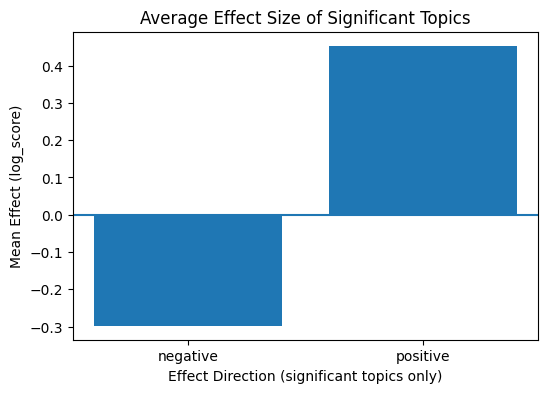

In [18]:
plt.figure(figsize=(6, 4))
plt.bar(summary["effect_direction"], summary["mean"])
plt.axhline(0)
plt.xlabel("Effect Direction (significant topics only)")
plt.ylabel("Mean Effect (log_score)")
plt.title("Average Effect Size of Significant Topics")
plt.show()

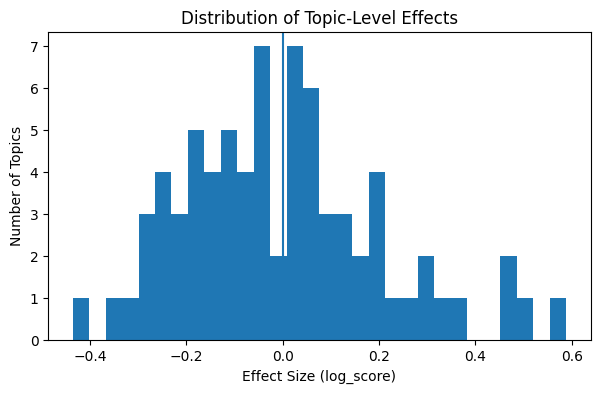

In [19]:
plt.figure(figsize=(7, 4))
plt.hist(ab_df["diff"], bins=30)
plt.axvline(0)
plt.xlabel("Effect Size (log_score)")
plt.ylabel("Number of Topics")
plt.title("Distribution of Topic-Level Effects")
plt.show()

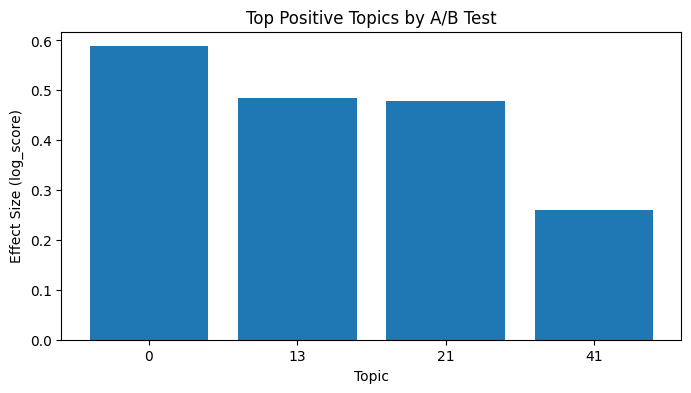

In [20]:
top_topics = (
    ab_df[
        (ab_df["significant"]) &
        (ab_df["diff"] > 0)
    ]
    .sort_values("diff", ascending=False)
    .head(10)
)

plt.figure(figsize=(8, 4))
plt.bar(top_topics["topic"].astype(str), top_topics["diff"])
plt.xlabel("Topic")
plt.ylabel("Effect Size (log_score)")
plt.title("Top Positive Topics by A/B Test")
plt.show()


In [21]:
sig_df = ab_df[ab_df["significant"]].sort_values("diff", ascending=False)
sig_df[["topic", "mean_A", "mean_B", "diff", "p_adj", "n_A"]]

,topic,mean_A,mean_B,diff,p_adj,n_A
0,0,2.104117,1.515999,0.588118,9.899794e-10,211
13,13,2.012566,1.526997,0.485568,7.483409e-03,99
21,21,2.006980,1.528413,0.478567,5.171676e-03,80
41,41,1.792940,1.532179,0.260761,3.549312e-02,47
10,10,1.310430,1.537467,-0.227037,4.036486e-02,107
2,2,1.312152,1.540153,-0.228001,1.326301e-03,188
20,20,1.265919,1.537170,-0.271251,3.549312e-02,82
7,7,1.213156,1.540826,-0.327670,4.784810e-05,145
35,35,1.101989,1.537226,-0.435238,9.049097e-04,52
